# SpaceX Falcon 9 First Stage Landing Prediction
## Lab 8: Machine Learning Prediction

This notebook builds a classification pipeline to predict whether the Falcon 9 first stage will land.

**Objectives**
- Standardize the data and split it into training and test sets
- Find the best hyperparameters for Logistic Regression, SVM, Decision Tree and K-Nearest Neighbours
- Compare the models on the test data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

In [2]:
def plot_confusion_matrix(y, y_predict, title='Confusion Matrix'):
    """Plot the confusion matrix for a set of predictions."""
    cm = confusion_matrix(y, y_predict)
    plt.figure(figsize=(5, 4))
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land', 'landed'])
    ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

In [3]:
data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
data.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [4]:
X = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv")
print(X.shape)
X.head()

(90, 83)


,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,Orbit_GTO,Orbit_HEO,Orbit_ISS,...,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062,GridFins_False,GridFins_True,Reused_False,Reused_True,Legs_False,Legs_True
0,1.0,6104.959412,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,2.0,525.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,3.0,677.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,4.0,500.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,5.0,3170.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


### Task 1: Create the label array from the `Class` column

In [5]:
Y = data['Class'].to_numpy()
Y[:10]

array([0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

### Task 2: Standardize the features

In [6]:
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)
X[:2]

array([[-1.71291154e+00, -1.94814463e-16, -6.53912840e-01,
        -1.57589457e+00, -9.73440458e-01, -1.05999788e-01,
        -1.05999788e-01, -6.54653671e-01, -1.05999788e-01,
        -5.51677284e-01,  3.44342023e+00, -1.85695338e-01,
        -3.33333333e-01, -1.05999788e-01, -2.42535625e-01,
        -4.29197538e-01,  7.97724035e-01, -5.68796459e-01,
        -4.10890702e-01, -4.10890702e-01, -1.50755672e-01,
        -7.97724035e-01, -1.50755672e-01, -3.92232270e-01,
         9.43398113e+00, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.50755672e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.50755672e-01, -1.05999788e-0

### Task 3: Split the data into training and test sets

In [7]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print("Training samples:", X_train.shape[0])
print("Test samples:", Y_test.shape[0])

Training samples: 72
Test samples: 18


### Task 4: Logistic Regression with GridSearchCV

In [8]:
parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}
lr = LogisticRegression()
logreg_cv = GridSearchCV(lr, parameters, cv=10)
logreg_cv.fit(X_train, Y_train)

print("tuned hyperparameters (best parameters):", logreg_cv.best_params_)
print("accuracy on validation data:", logreg_cv.best_score_)

tuned hyperparameters (best parameters): {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
accuracy on validation data: 0.8464285714285713


### Task 5: Logistic Regression accuracy on the test data and confusion matrix

Logistic Regression test accuracy: 0.8333333333333334


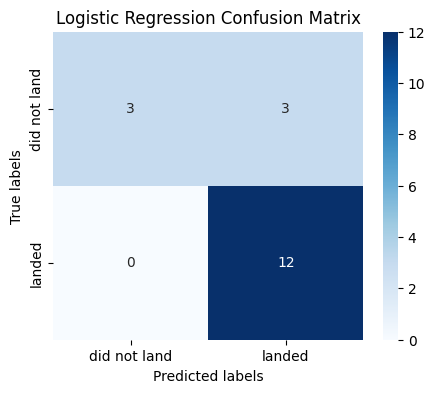

In [9]:
logreg_test_accuracy = logreg_cv.score(X_test, Y_test)
print("Logistic Regression test accuracy:", logreg_test_accuracy)

yhat = logreg_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat, 'Logistic Regression Confusion Matrix')

### Task 6: Support Vector Machine with GridSearchCV

In [10]:
parameters = {'kernel': ('linear', 'rbf', 'poly', 'sigmoid'),
              'C': np.logspace(-3, 3, 5),
              'gamma': np.logspace(-3, 3, 5)}
svm = SVC()
svm_cv = GridSearchCV(svm, parameters, cv=10)
svm_cv.fit(X_train, Y_train)

print("tuned hyperparameters (best parameters):", svm_cv.best_params_)
print("accuracy on validation data:", svm_cv.best_score_)

tuned hyperparameters (best parameters): {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
accuracy on validation data: 0.8482142857142856


### Task 7: SVM accuracy on the test data and confusion matrix

SVM test accuracy: 0.8333333333333334


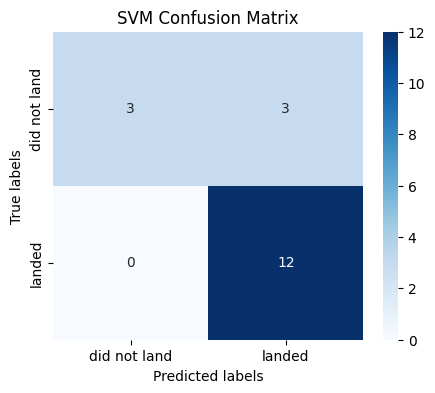

In [11]:
svm_test_accuracy = svm_cv.score(X_test, Y_test)
print("SVM test accuracy:", svm_test_accuracy)

yhat = svm_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat, 'SVM Confusion Matrix')

### Task 8: Decision Tree with GridSearchCV

In [12]:
parameters = {'criterion': ['gini', 'entropy'],
              'splitter': ['best', 'random'],
              'max_depth': [2 * n for n in range(1, 10)],
              'max_features': ['sqrt', 'log2'],
              'min_samples_leaf': [1, 2, 4],
              'min_samples_split': [2, 5, 10]}
tree = DecisionTreeClassifier(random_state=0)
tree_cv = GridSearchCV(tree, parameters, cv=10)
tree_cv.fit(X_train, Y_train)

print("tuned hyperparameters (best parameters):", tree_cv.best_params_)
print("accuracy on validation data:", tree_cv.best_score_)

tuned hyperparameters (best parameters): {'criterion': 'gini', 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy on validation data: 0.875


### Task 9: Decision Tree accuracy on the test data and confusion matrix

Decision Tree test accuracy: 0.8333333333333334


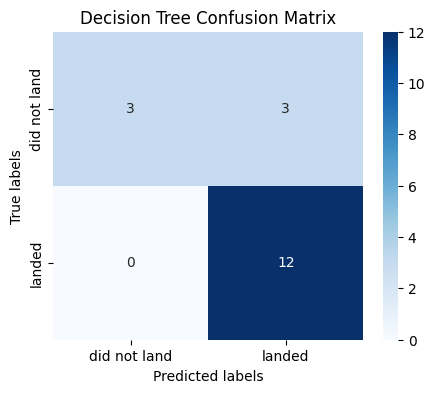

In [13]:
tree_test_accuracy = tree_cv.score(X_test, Y_test)
print("Decision Tree test accuracy:", tree_test_accuracy)

yhat = tree_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat, 'Decision Tree Confusion Matrix')

### Task 10: K-Nearest Neighbours with GridSearchCV

In [14]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
              'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
              'p': [1, 2]}
KNN = KNeighborsClassifier()
knn_cv = GridSearchCV(KNN, parameters, cv=10)
knn_cv.fit(X_train, Y_train)

print("tuned hyperparameters (best parameters):", knn_cv.best_params_)
print("accuracy on validation data:", knn_cv.best_score_)

tuned hyperparameters (best parameters): {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
accuracy on validation data: 0.8482142857142858


### Task 11: KNN accuracy on the test data and confusion matrix

KNN test accuracy: 0.8333333333333334


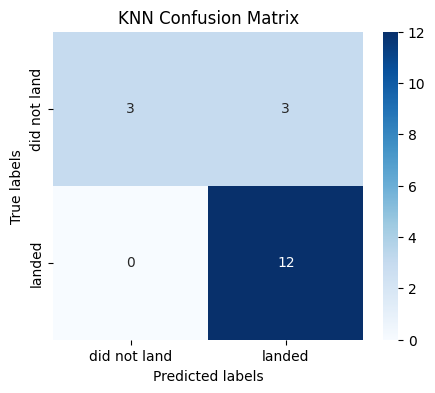

In [15]:
knn_test_accuracy = knn_cv.score(X_test, Y_test)
print("KNN test accuracy:", knn_test_accuracy)

yhat = knn_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat, 'KNN Confusion Matrix')

### Task 12: Find the method that performs best

In [16]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN'],
    'Validation Accuracy (CV=10)': [logreg_cv.best_score_, svm_cv.best_score_, tree_cv.best_score_, knn_cv.best_score_],
    'Test Accuracy': [logreg_test_accuracy, svm_test_accuracy, tree_test_accuracy, knn_test_accuracy]
}).round(4)
results

,Model,Validation Accuracy (CV=10),Test Accuracy
0,Logistic Regression,0.8464,0.8333
1,SVM,0.8482,0.8333
2,Decision Tree,0.8750,0.8333
3,KNN,0.8482,0.8333


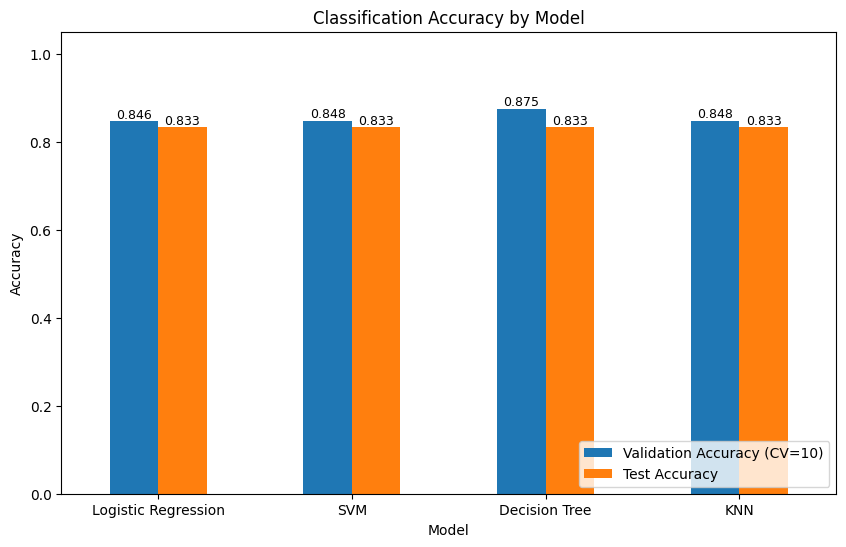

In [17]:
ax = results.set_index('Model').plot(kind='bar', figsize=(10, 6), rot=0)
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.05)
ax.set_title('Classification Accuracy by Model')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=9)
plt.legend(loc='lower right')
plt.show()

In [18]:
best = results.sort_values(['Test Accuracy', 'Validation Accuracy (CV=10)'], ascending=False).iloc[0]
print("Best performing model:", best['Model'])
print("Test accuracy:", best['Test Accuracy'], "| Validation accuracy:", best['Validation Accuracy (CV=10)'])

Best performing model: Decision Tree
Test accuracy: 0.8333 | Validation accuracy: 0.875
